# UCS420 – Cognitive Computing | Assignment 10
## Heart Health Information Assistant

**For even roll numbers** · Roll number: **1024160094**

Run the notebook from top to bottom in Google Colab. It includes the labelled corpus, taxonomy, domain concepts and relationships, NLP preprocessing, TF-IDF classifier, evaluation, knowledge base, reasoning rules, test cases and interactive interface.

> Educational prototype only. It does not diagnose medical conditions. For emergencies, contact local emergency services.

In [1]:
# UCS420 - Cognitive Computing | Assignment 10
# Heart Health Information Assistant (EVEN roll numbers)
# Google Colab-ready implementation

## --------------------------- 1. INSTALL / IMPORT ---------------------------

In [2]:
# Run this cell in Google Colab. NLTK resources are downloaded below.

import re
import warnings
warnings.filterwarnings("ignore")

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

## --------------------------- 2. LABELLED CORPUS ---------------------------

In [3]:
# 8 intents x 10 example queries = 80 labelled queries.

data = {
    "symptoms": [
        "What are common symptoms of heart disease?",
        "Why do I feel shortness of breath?",
        "Can chest discomfort be a sign of a heart problem?",
        "What does an irregular heartbeat feel like?",
        "Why am I experiencing unusual fatigue?",
        "Can swollen ankles be related to heart health?",
        "What are signs of poor blood circulation?",
        "Why do I feel dizzy sometimes?",
        "What symptoms can indicate heart failure?",
        "Can palpitations happen with heart conditions?"
    ],
    "prevention": [
        "How can I keep my heart healthy?",
        "What habits help prevent heart disease?",
        "How can I reduce my risk of a heart attack?",
        "What lifestyle changes protect the heart?",
        "How important is regular health screening?",
        "How can I maintain healthy cholesterol levels?",
        "What daily habits improve cardiovascular health?",
        "Does quitting smoking help the heart?",
        "How can stress management support heart health?",
        "What are simple ways to prevent cardiovascular disease?"
    ],
    "nutrition": [
        "Which foods are good for the heart?",
        "What is a heart healthy diet?",
        "Should I reduce salt in my food?",
        "Are fruits and vegetables good for cardiovascular health?",
        "Which foods contain healthy fats?",
        "Is eating too much saturated fat harmful?",
        "What should I eat to manage cholesterol?",
        "Are whole grains beneficial for the heart?",
        "How much salt should I consume?",
        "Is a balanced diet important for heart health?"
    ],
    "exercise": [
        "How much exercise is good for the heart?",
        "Is walking beneficial for cardiovascular health?",
        "Can regular physical activity lower heart disease risk?",
        "What exercises improve heart fitness?",
        "Should beginners start with light exercise?",
        "Does cycling help improve heart health?",
        "How often should adults be physically active?",
        "Can exercise help control blood pressure?",
        "Is swimming a good cardiovascular workout?",
        "Why is physical activity important for the heart?"
    ],
    "medication": [
        "Why are blood pressure medicines prescribed?",
        "What should I know before taking heart medication?",
        "Can I stop my prescribed heart medicine?",
        "What are blood thinners used for?",
        "Why might a doctor prescribe cholesterol medication?",
        "Should I take medicine exactly as prescribed?",
        "Can heart medicines have side effects?",
        "What should I do if I miss a prescribed dose?",
        "Why do some patients take beta blockers?",
        "Can I change my heart medicine dosage myself?"
    ],
    "tests": [
        "What is an ECG test?",
        "Why is an echocardiogram performed?",
        "What does a cholesterol blood test measure?",
        "How does a stress test check the heart?",
        "What is a blood pressure reading?",
        "Why might a doctor recommend a Holter monitor?",
        "What can an angiogram detect?",
        "How is heart function examined?",
        "What is the purpose of a cardiac blood test?",
        "Do I need a doctor to interpret an ECG?"
    ],
    "risk_factors": [
        "Does smoking increase the risk of heart disease?",
        "Can high blood pressure damage the heart?",
        "Is high cholesterol a heart disease risk factor?",
        "Does family history affect heart disease risk?",
        "How does diabetes affect cardiovascular health?",
        "Can obesity increase heart disease risk?",
        "Does age influence cardiovascular risk?",
        "Can long term stress affect the heart?",
        "Is physical inactivity a risk factor?",
        "How does excessive alcohol affect heart health?"
    ],
    "general": [
        "What does cardiovascular mean?",
        "What is the function of the human heart?",
        "How does the heart pump blood?",
        "What is the cardiovascular system?",
        "Why is the heart important?",
        "How many chambers does the human heart have?",
        "What is coronary artery disease?",
        "What is a normal resting heart rate?",
        "What is blood circulation?",
        "Explain heart health in simple words."
    ]
}

rows = []
for intent, queries in data.items():
    for query in queries:
        rows.append({"query": query, "intent": intent})

corpus = pd.DataFrame(rows)
print("Total labelled queries:", len(corpus))
print("\nQueries per intent:")
print(corpus["intent"].value_counts())

Total labelled queries: 80

Queries per intent:
intent
symptoms        10
prevention      10
nutrition       10
exercise        10
medication      10
tests           10
risk_factors    10
general         10
Name: count, dtype: int64


## --------------------------- 3. HIERARCHICAL TAXONOMY ---------------------------

In [4]:
taxonomy = {
    "Heart Health": {
        "Heart conditions": ["symptoms", "tests"],
        "Heart care": ["prevention", "nutrition"],
    },
    "Lifestyle": {
        "Physical activity": ["exercise"],
        "Health habits and risks": ["risk_factors"],
    },
    "Clinical management": {
        "Medicines": ["medication"],
        "Clinical information": ["general"],
    },
    "Patient support": {
        "Understanding symptoms": ["symptoms"],
        "Understanding treatment and diagnosis": ["tests", "medication"],
    }
}

print("\nHIERARCHICAL TAXONOMY")
for major, subcategories in taxonomy.items():
    print(f"\n{major}")
    for sub, intents in subcategories.items():
        print(f"  - {sub}: {', '.join(intents)}")


HIERARCHICAL TAXONOMY

Heart Health
  - Heart conditions: symptoms, tests
  - Heart care: prevention, nutrition

Lifestyle
  - Physical activity: exercise
  - Health habits and risks: risk_factors

Clinical management
  - Medicines: medication
  - Clinical information: general

Patient support
  - Understanding symptoms: symptoms
  - Understanding treatment and diagnosis: tests, medication


## --------------------------- 4. DOMAIN CONCEPTS AND RELATIONSHIPS ---------------------------

In [5]:
domain_concepts = [
    "Heart", "Blood", "Blood Pressure", "Cholesterol", "Arteries",
    "Exercise", "Nutrition", "Medication", "ECG", "Cardiovascular Disease",
    "Smoking", "Doctor"
]

relationships = [
    ("Heart", "pumps", "Blood"),
    ("Blood", "flows through", "Arteries"),
    ("Blood Pressure", "measures pressure of", "Blood"),
    ("High Blood Pressure", "can increase risk of", "Cardiovascular Disease"),
    ("High Cholesterol", "can contribute to narrowing of", "Arteries"),
    ("Exercise", "supports health of", "Heart"),
    ("Nutrition", "influences", "Cholesterol"),
    ("Medication", "may be prescribed by", "Doctor"),
    ("ECG", "records electrical activity of", "Heart"),
    ("Smoking", "increases risk of", "Cardiovascular Disease"),
    ("Doctor", "may recommend", "ECG"),
    ("Cardiovascular Disease", "can affect", "Heart")
]

print("\nDOMAIN CONCEPTS:")
for concept in domain_concepts:
    print("-", concept)

print("\nDOMAIN RELATIONSHIPS:")
for subject, relation, obj in relationships:
    print(f"{subject} --{relation}--> {obj}")


DOMAIN CONCEPTS:
- Heart
- Blood
- Blood Pressure
- Cholesterol
- Arteries
- Exercise
- Nutrition
- Medication
- ECG
- Cardiovascular Disease
- Smoking
- Doctor

DOMAIN RELATIONSHIPS:
Heart --pumps--> Blood
Blood --flows through--> Arteries
Blood Pressure --measures pressure of--> Blood
High Blood Pressure --can increase risk of--> Cardiovascular Disease
High Cholesterol --can contribute to narrowing of--> Arteries
Exercise --supports health of--> Heart
Nutrition --influences--> Cholesterol
Medication --may be prescribed by--> Doctor
ECG --records electrical activity of--> Heart
Smoking --increases risk of--> Cardiovascular Disease
Doctor --may recommend--> ECG
Cardiovascular Disease --can affect--> Heart


## --------------------------- 5. NLP PREPROCESSING ---------------------------

In [6]:
STOP_WORDS = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    """Lowercase, tokenize, remove stopwords and lemmatize."""
    text = text.lower()
    tokens = word_tokenize(text)
    cleaned = []
    for token in tokens:
        if token.isalpha() and token not in STOP_WORDS:
            cleaned.append(lemmatizer.lemmatize(token))
    return " ".join(cleaned)

corpus["processed_query"] = corpus["query"].apply(preprocess_text)

print("\nPREPROCESSING EXAMPLE")
print("Original :", corpus.loc[0, "query"])
print("Processed:", corpus.loc[0, "processed_query"])


PREPROCESSING EXAMPLE
Original : What are common symptoms of heart disease?
Processed: common symptom heart disease


## --------------------------- 6. TF-IDF + CLASSIFIER ---------------------------

In [7]:
X = corpus["processed_query"]
y = corpus["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## --------------------------- 7. MODEL EVALUATION ---------------------------


MODEL EVALUATION
Accuracy : 0.4500
Precision: 0.5393
Recall   : 0.4500
F1-score : 0.4439

Classification Report:
              precision    recall  f1-score   support

    exercise       0.14      0.50      0.22         2
     general       0.50      0.50      0.50         2
  medication       1.00      0.67      0.80         3
   nutrition       0.50      0.33      0.40         3
  prevention       0.00      0.00      0.00         3
risk_factors       0.50      1.00      0.67         2
    symptoms       1.00      0.33      0.50         3
       tests       0.50      0.50      0.50         2

    accuracy                           0.45        20
   macro avg       0.52      0.48      0.45        20
weighted avg       0.54      0.45      0.44        20



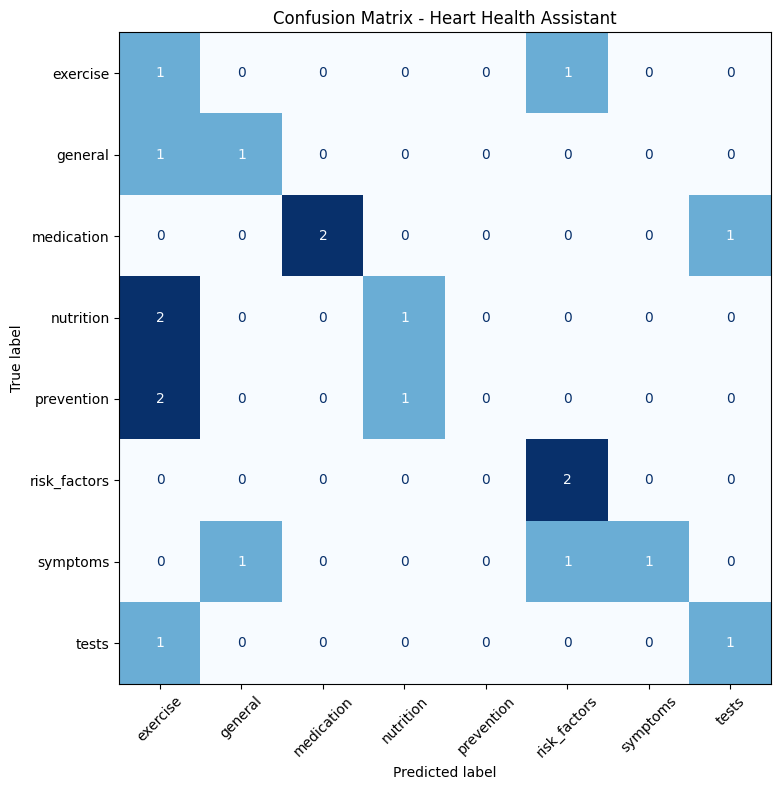

In [8]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("\nMODEL EVALUATION")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(corpus["intent"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix - Heart Health Assistant")
plt.tight_layout()
plt.show()

## --------------------------- 8. DOMAIN-SPECIFIC KNOWLEDGE BASE ---------------------------

In [9]:
knowledge_base = {
    "symptoms": (
        "Possible heart-related symptoms include chest discomfort, shortness of breath, "
        "palpitations, unusual fatigue, dizziness and swelling in the legs or ankles. "
        "These symptoms can have many causes. A healthcare professional should assess "
        "persistent, new or concerning symptoms."
    ),
    "prevention": (
        "Heart-health habits include avoiding tobacco, staying physically active, "
        "eating a balanced diet, maintaining a healthy weight, managing stress and "
        "checking blood pressure and cholesterol with a healthcare professional."
    ),
    "nutrition": (
        "A heart-friendly eating pattern generally emphasizes vegetables, fruits, "
        "whole grains, beans, nuts and appropriate sources of unsaturated fats. "
        "Limit excess salt, added sugars and foods high in saturated or trans fats. "
        "Individual dietary needs can vary."
    ),
    "exercise": (
        "Regular physical activity supports cardiovascular health. Many adults are "
        "advised to aim for at least 150 minutes of moderate-intensity activity per week, "
        "if appropriate for their health. Start gradually and ask a clinician before "
        "starting strenuous exercise if you have symptoms or a medical condition."
    ),
    "medication": (
        "Heart medicines may be used to manage blood pressure, cholesterol, rhythm "
        "problems or clotting risk. Take medicines only as prescribed. Do not stop, "
        "start or change a dose without advice from your doctor or pharmacist."
    ),
    "tests": (
        "Common heart assessments include blood pressure measurement, ECG, "
        "echocardiogram, cholesterol blood tests, stress tests and sometimes Holter "
        "monitoring or angiography. The appropriate test depends on symptoms and "
        "clinical assessment; a clinician interprets the results."
    ),
    "risk_factors": (
        "Heart disease risk factors can include high blood pressure, high cholesterol, "
        "smoking, diabetes, obesity, physical inactivity, age and family history. "
        "Some risk factors can be modified through lifestyle changes and medical care."
    ),
    "general": (
        "The heart is a muscular organ that pumps blood through the circulatory system. "
        "The cardiovascular system includes the heart and blood vessels. For personal "
        "health concerns, consult a qualified healthcare professional."
    )
}

## --------------------------- 9. REASONING RULES ---------------------------

In [10]:
EMERGENCY_KEYWORDS = [
    "severe chest pain", "chest pain", "chest pressure", "can't breathe",
    "cannot breathe", "difficulty breathing", "shortness of breath",
    "fainting", "unconscious", "stroke", "face drooping",
    "weakness on one side", "sudden severe"
]

HEART_DOMAIN_KEYWORDS = [
    "heart", "cardiac", "cardiovascular", "blood pressure", "cholesterol",
    "chest", "pulse", "ecg", "ekg", "artery", "arteries", "blood circulation",
    "heart rate", "palpitation", "exercise", "smoking", "diet", "salt",
    "medicine", "medication", "symptom", "blood", "stroke"
]

def is_emergency(query):
    q = query.lower()
    return any(keyword in q for keyword in EMERGENCY_KEYWORDS)

def is_heart_related(query):
    q = query.lower()
    return any(keyword in q for keyword in HEART_DOMAIN_KEYWORDS)

def get_assistant_response(query):
    # Rule 1: Emergency escalation takes priority over ML classification.
    if is_emergency(query):
        return (
            "EMERGENCY ALERT: This may describe a medical emergency. "
            "Call your local emergency number immediately (112 in India) or seek "
            "emergency medical care now. Do not drive yourself. Do not wait for this "
            "assistant or an online response. This assistant cannot diagnose you."
        )

    # Rule 2: Reject queries clearly outside the assistant's heart-health scope.
    if not is_heart_related(query):
        return (
            "I can answer general heart-health questions only. Please ask about "
            "heart symptoms, prevention, nutrition, exercise, medicines, tests or "
            "cardiovascular risk factors."
        )

    # NLP preprocessing + intent classification.
    processed = preprocess_text(query)
    probabilities = model.predict_proba([processed])[0]
    best_index = int(np.argmax(probabilities))
    confidence = float(probabilities[best_index])
    predicted_intent = model.classes_[best_index]

    # Rule 3: Low-confidence handling.
    if confidence < 0.20:
        return (
            "I am not sufficiently confident about the meaning of your question. "
            "Please rephrase it or consult a healthcare professional."
        )

    # Rule 4: Knowledge-base retrieval based on predicted intent.
    response = knowledge_base.get(predicted_intent)

    # Rule 5: Unsupported intent / missing knowledge-base entry.
    if response is None:
        return "I do not have reliable information for that query. Please consult a clinician."

    # Rule 6: Add confidence and safety disclaimer.
    return (
        f"Detected intent: {predicted_intent.replace('_', ' ').title()}\n"
        f"Model confidence: {confidence:.2f}\n\n"
        f"{response}\n\n"
        "Disclaimer: This is general educational information, not a diagnosis or "
        "a substitute for advice from a qualified healthcare professional."
    )

print("\nREASONING RULES IMPLEMENTED:")
print("1. Emergency keyword detection and escalation.")
print("2. Heart-health domain validation.")
print("3. Low-confidence query handling.")
print("4. Intent-based knowledge-base retrieval.")
print("5. Unsupported intent / missing knowledge handling.")
print("6. Safety disclaimer for normal responses.")


REASONING RULES IMPLEMENTED:
1. Emergency keyword detection and escalation.
2. Heart-health domain validation.
3. Low-confidence query handling.
4. Intent-based knowledge-base retrieval.
5. Unsupported intent / missing knowledge handling.
6. Safety disclaimer for normal responses.


## --------------------------- 10. INTEGRATED ASSISTANT ---------------------------

In [11]:
def heart_health_assistant():
    print("=" * 65)
    print("       HEART HEALTH INFORMATION ASSISTANT")
    print("Type 'exit' to stop.")
    print("=" * 65)

    while True:
        query = input("\nYou: ").strip()
        if query.lower() in ["exit", "quit", "bye"]:
            print("Assistant: Take care. Stay healthy!")
            break
        if not query:
            print("Assistant: Please enter a question.")
            continue
        print("\nAssistant:", get_assistant_response(query))

## --------------------------- 11. REQUIRED TEST CASES ---------------------------

In [12]:
test_queries = [
    ("Intent: symptoms", "What are common signs of heart disease?"),
    ("Intent: prevention", "How do I protect my cardiovascular system?"),
    ("Intent: nutrition", "Which foods support a healthy heart?"),
    ("Intent: exercise", "Is daily walking useful for my heart?"),
    ("Intent: medication", "Should I stop taking my prescribed heart medicine?"),
    ("Intent: tests", "Can an ECG check the electrical activity of my heart?"),
    ("Intent: risk factors", "Does tobacco use raise cardiovascular risk?"),
    ("Intent: general", "What does the heart do in the human body?"),
    ("Differently worded query", "What lifestyle choices keep my ticker healthy?"),
    ("Unsupported query", "How do I repair a car engine?"),
    ("Low-confidence / vague query", "heart xyz qqq"),
    ("Emergency query", "I have severe chest pain and difficulty breathing.")
]

print("\n" + "=" * 65)
print("REQUIRED ASSIGNMENT TESTS")
print("=" * 65)

for test_name, query in test_queries:
    print(f"\n[{test_name}]")
    print("Query:", query)
    print("Response:", get_assistant_response(query))


REQUIRED ASSIGNMENT TESTS

[Intent: symptoms]
Query: What are common signs of heart disease?
Response: I am not sufficiently confident about the meaning of your question. Please rephrase it or consult a healthcare professional.

[Intent: prevention]
Query: How do I protect my cardiovascular system?
Response: Detected intent: General
Model confidence: 0.23

The heart is a muscular organ that pumps blood through the circulatory system. The cardiovascular system includes the heart and blood vessels. For personal health concerns, consult a qualified healthcare professional.

Disclaimer: This is general educational information, not a diagnosis or a substitute for advice from a qualified healthcare professional.

[Intent: nutrition]
Query: Which foods support a healthy heart?
Response: I am not sufficiently confident about the meaning of your question. Please rephrase it or consult a healthcare professional.

[Intent: exercise]
Query: Is daily walking useful for my heart?
Response: I am not

## --------------------------- 12. INTERACTIVE COLAB INTERFACE ---------------------------

In [13]:
# Run this section in Google Colab for a chat-style input interface.

try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    question_box = widgets.Text(
        placeholder="Ask a heart-health question...",
        description="You:",
        layout=widgets.Layout(width="85%")
    )
    send_button = widgets.Button(
        description="Ask",
        button_style="success",
        tooltip="Submit your question"
    )
    output_area = widgets.Output()

    def on_send_clicked(_):
        query = question_box.value.strip()
        if not query:
            return
        with output_area:
            print("\nYou:", query)
            print("Assistant:", get_assistant_response(query))
        question_box.value = ""

    send_button.on_click(on_send_clicked)
    display(widgets.VBox([
        widgets.HTML("<h3>Heart Health Information Assistant</h3>"),
        widgets.HBox([question_box, send_button]),
        output_area
    ]))

except ImportError:
    print("ipywidgets is unavailable. Use heart_health_assistant() for text interaction.")

# To use the terminal-style interactive assistant instead, run:
# heart_health_assistant()